In [ ]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.1/38.1 MB 13.0 MB/s eta 0:00:00


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving bbbp.csv to bbbp.csv


In [ ]:
import pandas as pd

df = pd.read_csv("bbbp.csv")

print("Number of records:", len(df))
print(df.head())

Number of records: 2039
                                              SMILES  label
0                   [Cl].CC(C)NCC(O)COc1cccc2ccccc12      1
1           C(=O)(OC(C)(C)C)CCCc1ccc(cc1)N(CCCl)CCCl      1
2  c12c3c(N4CCN(C)CC4)c(F)cc1c(c(C(O)=O)cn2C(C)CO...      1
3                   C1CCN(CC1)Cc1cccc(c1)OCCCNC(=O)C      1
4  Cc1onc(c2ccccc2Cl)c1C(=O)N[C@H]3[C@H]4SC(C)(C)...      1


In [ ]:
from rdkit import Chem

print("RDKit installed successfully!")

RDKit installed successfully!


In [ ]:
print(df["label"].value_counts())

label
1    1560
0     479
Name: count, dtype: int64


In [ ]:
import os

os.makedirs("/content/chemical_images/0", exist_ok=True)
os.makedirs("/content/chemical_images/1", exist_ok=True)

print("Folders created successfully!")

Folders created successfully!


In [ ]:
from rdkit import Chem
from rdkit.Chem import Draw
from tqdm import tqdm

success = 0
failed = 0

for index, row in tqdm(df.iterrows(), total=len(df)):

    smiles = row["SMILES"]
    label = row["label"]

    # Convert SMILES to molecule
    mol = Chem.MolFromSmiles(smiles)

    # Check if SMILES is valid
    if mol is None:
        failed += 1
        continue

    # Generate image
    img = Draw.MolToImage(mol, size=(224, 224))

    # Save image
    filename = f"/content/chemical_images/{label}/molecule_{index}.png"
    img.save(filename)

    success += 1

print("Successfully generated:", success)
print("Failed:", failed)

 15%|█▌        | 306/2039 [00:01<00:10, 171.42it/s][06:15:20] WARNING: not removing hydrogen atom without neighbors
[06:15:20] WARNING: not removing hydrogen atom without neighbors
[06:15:20] WARNING: not removing hydrogen atom without neighbors
 32%|███▏      | 648/2039 [00:03<00:08, 167.78it/s][06:15:22] WARNING: not removing hydrogen atom without neighbors
[06:15:22] WARNING: not removing hydrogen atom without neighbors
 45%|████▌     | 925/2039 [00:05<00:08, 128.57it/s][06:15:24] WARNING: not removing hydrogen atom without neighbors
[06:15:24] WARNING: not removing hydrogen atom without neighbors
 58%|█████▊    | 1184/2039 [00:07<00:05, 169.51it/s][06:15:25] WARNING: not removing hydrogen atom without neighbors
[06:15:25] WARNING: not removing hydrogen atom without neighbors
 63%|██████▎   | 1291/2039 [00:07<00:04, 167.65it/s][06:15:26] WARNING: not removing hydrogen atom without neighbors
[06:15:26] WARNING: not removing hydrogen atom without neighbors
 79%|███████▉  | 1610/2039 [

Successfully generated: 2039
Failed: 0


In [ ]:
import os

print("Class 0:", len(os.listdir("/content/chemical_images/0")))
print("Class 1:", len(os.listdir("/content/chemical_images/1")))

Class 0: 479
Class 1: 1560


In [ ]:
print("Total images:",
      len(os.listdir("/content/chemical_images/0")) +
      len(os.listdir("/content/chemical_images/1")))

Total images: 2039


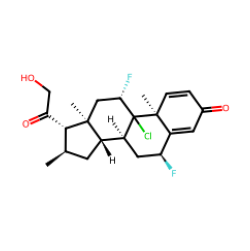

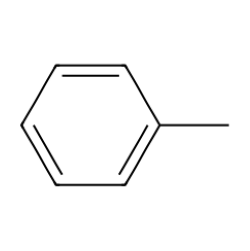

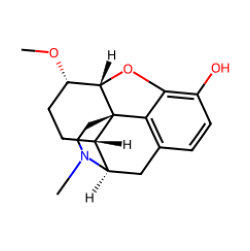

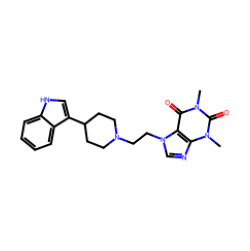

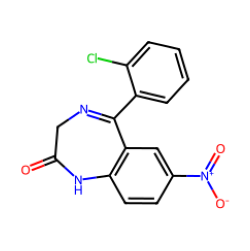

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import glob

files = glob.glob("/content/chemical_images/1/*.png")

for file in files[:5]:
    img = Image.open(file)
    plt.figure(figsize=(3,3))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

In [ ]:
from rdkit import Chem
from rdkit.Chem import Draw
from tqdm import tqdm

success = 0
failed = 0

for index, row in tqdm(df.iterrows(), total=len(df)):

    smiles = row["SMILES"]
    label = row["label"]

    # Convert SMILES to molecule
    mol = Chem.MolFromSmiles(smiles)

    # Skip invalid SMILES
    if mol is None:
        failed += 1
        continue

    # Generate 224 × 224 image
    img = Draw.MolToImage(mol, size=(224, 224))

    # Save image in the corresponding class folder
    filename = f"/content/chemical_images/{label}/molecule_{index}.png"
    img.save(filename)

    success += 1

print("Successfully generated:", success)
print("Failed:", failed)

 15%|█▍        | 299/2039 [00:01<00:10, 173.20it/s][06:15:46] WARNING: not removing hydrogen atom without neighbors
[06:15:46] WARNING: not removing hydrogen atom without neighbors
[06:15:46] WARNING: not removing hydrogen atom without neighbors
 31%|███       | 631/2039 [00:03<00:08, 171.29it/s][06:15:48] WARNING: not removing hydrogen atom without neighbors
[06:15:48] WARNING: not removing hydrogen atom without neighbors
 46%|████▌     | 928/2039 [00:05<00:08, 129.80it/s][06:15:49] WARNING: not removing hydrogen atom without neighbors
[06:15:49] WARNING: not removing hydrogen atom without neighbors
 58%|█████▊    | 1191/2039 [00:07<00:04, 170.03it/s][06:15:51] WARNING: not removing hydrogen atom without neighbors
[06:15:51] WARNING: not removing hydrogen atom without neighbors
 64%|██████▎   | 1297/2039 [00:07<00:04, 167.81it/s][06:15:52] WARNING: not removing hydrogen atom without neighbors
[06:15:52] WARNING: not removing hydrogen atom without neighbors
 79%|███████▉  | 1617/2039 [

Successfully generated: 2039
Failed: 0


In [ ]:
import os

class_0 = len(os.listdir("/content/chemical_images/0"))
class_1 = len(os.listdir("/content/chemical_images/1"))

print("Class 0 images:", class_0)
print("Class 1 images:", class_1)
print("Total images:", class_0 + class_1)

Class 0 images: 479
Class 1 images: 1560
Total images: 2039


Class 0 - showing 5 images


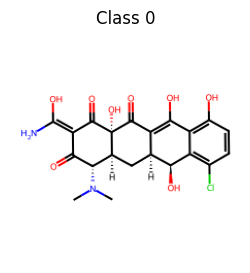

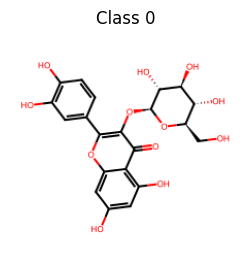

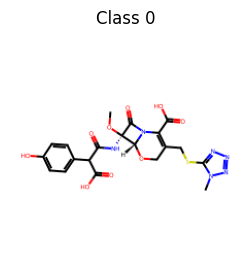

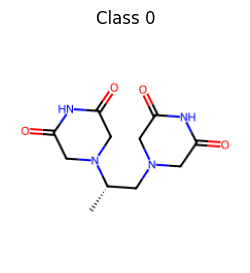

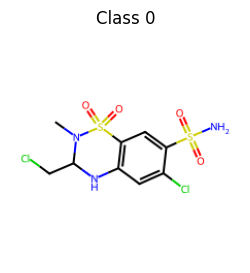

Class 1 - showing 5 images


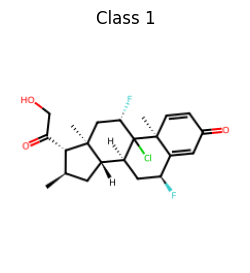

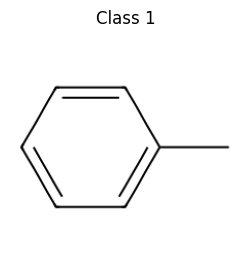

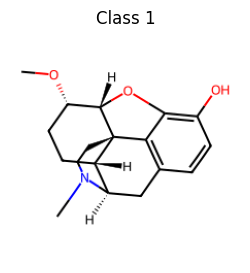

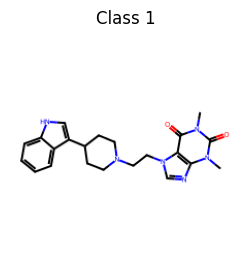

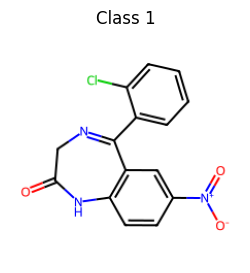

In [ ]:
import glob
import matplotlib.pyplot as plt
from PIL import Image

for label in ["0", "1"]:

    files = glob.glob(f"/content/chemical_images/{label}/*.png")

    print(f"Class {label} - showing 5 images")

    for file in files[:5]:
        img = Image.open(file)

        plt.figure(figsize=(3, 3))
        plt.imshow(img)
        plt.title(f"Class {label}")
        plt.axis("off")
        plt.show()

In [ ]:
import shutil

shutil.make_archive(
    "/content/chemical_images",
    "zip",
    "/content/chemical_images"
)

print("ZIP file created!")

ZIP file created!


In [ ]:
# from google.colab import files

# files.download("/content/chemical_images.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#Checking Class Balance
import os

class_0 = len(os.listdir("/content/chemical_images/0"))
class_1 = len(os.listdir("/content/chemical_images/1"))

print("Class 0:", class_0)
print("Class 1:", class_1)
print("Total:", class_0 + class_1)

Class 0: 479
Class 1: 1560
Total: 2039


In [ ]:
#splitting molecular images into Training, Validation, and Testing sets
import os
import shutil
from sklearn.model_selection import train_test_split

# Source folder
source_dir = "/content/chemical_images"

# Destination folder
dataset_dir = "/content/dataset"

# Create folders
for split in ["train", "validation", "test"]:
    for label in ["0", "1"]:
        os.makedirs(f"{dataset_dir}/{split}/{label}", exist_ok=True)

# Get all image paths and their labels
image_paths = []
labels = []

for label in ["0", "1"]:
    folder = f"{source_dir}/{label}"

    for image in os.listdir(folder):
        image_paths.append(os.path.join(folder, image))
        labels.append(label)

# First split: 70% training, 30% temporary
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

# Second split: 15% validation, 15% testing
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    stratify=temp_labels,
    random_state=42
)

# Function to copy images
def copy_images(paths, labels, split):
    for image_path, label in zip(paths, labels):
        destination = f"{dataset_dir}/{split}/{label}"
        shutil.copy(image_path, destination)

# Copy images
copy_images(train_paths, train_labels, "train")
copy_images(val_paths, val_labels, "validation")
copy_images(test_paths, test_labels, "test")

print("Dataset splitting completed!")

Dataset splitting completed!


In [ ]:
for split in ["train", "validation", "test"]:

    class_0 = len(os.listdir(f"/content/dataset/{split}/0"))
    class_1 = len(os.listdir(f"/content/dataset/{split}/1"))

    print(f"\n{split.upper()}")
    print("Class 0:", class_0)
    print("Class 1:", class_1)
    print("Total:", class_0 + class_1)


TRAIN
Class 0: 335
Class 1: 1092
Total: 1427

VALIDATION
Class 0: 72
Class 1: 234
Total: 306

TEST
Class 0: 72
Class 1: 234
Total: 306


In [ ]:
!pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 878.5 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 142.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 104.0 MB/s eta 0:00:00
  Attempting uninstall: h5py
    Found existing installation: h5py 3.16.0
    Uninstalling h5py-3.16.0:
      Successfully uninstalled h5py-3.16.0


In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:86: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


TensorFlow version: 2.21.0


In [ ]:
#setting image parameters
IMG_SIZE = (224, 224)#size of every image given to CNN
BATCH_SIZE = 32 #CNN processes 32 images at a time

In [ ]:
#Loading the training images
train_data = tf.keras.utils.image_dataset_from_directory(
    "/content/dataset/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

Found 1427 files belonging to 2 classes.


In [ ]:
#Loading validation images
val_data = tf.keras.utils.image_dataset_from_directory(
    "/content/dataset/validation",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

Found 306 files belonging to 2 classes.


In [ ]:
#Loading test images
test_data = tf.keras.utils.image_dataset_from_directory(
    "/content/dataset/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

Found 306 files belonging to 2 classes.


In [ ]:
#checking class names
print("Classes:", train_data.class_names)

Classes: ['0', '1']


In [ ]:
#Check one batch of images
for images, labels in train_data.take(2):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)

Image shape: (32, 224, 224, 3)
Label shape: (32, 1)
Image shape: (32, 224, 224, 3)
Label shape: (32, 1)


CNN MODEL

In [ ]:
#creating CNN
from tensorflow.keras import layers, models

model = models.Sequential([

    # Input + First Convolution block
    layers.Input(shape=(224, 224, 3)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Second Convolution block
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Third Convolution block
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into one-dimensional vector
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(128, activation="relu"),

    # Prevent overfitting
    layers.Dropout(0.5),

    # Binary classification output
    layers.Dense(1, activation="sigmoid")
])

In [ ]:
#viewing the model
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#calculating class weights
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Your class labels
classes = np.array([0, 1])

# Number of samples in each class
class_counts = np.array([479, 1560])

# Calculate class weights
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=np.repeat(classes, class_counts)
)

class_weights = {
    0: weights[0],
    1: weights[1]
}

print("Class weights:", class_weights)

Class weights: {0: np.float64(2.12839248434238), 1: np.float64(0.653525641025641)}


In [ ]:
#compiling CNN
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=20,
    class_weight=class_weights
)

Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 125s 3s/step - accuracy: 0.4891 - loss: 52.1842 - val_accuracy: 0.4314 - val_loss: 0.7036
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 110s 2s/step - accuracy: 0.4562 - loss: 0.6862 - val_accuracy: 0.4412 - val_loss: 0.6948
Epoch 3/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 111s 2s/step - accuracy: 0.2628 - loss: 0.6928 - val_accuracy: 0.2353 - val_loss: 0.6949
Epoch 4/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 140s 2s/step - accuracy: 0.2866 - loss: 0.6928 - val_accuracy: 0.2941 - val_loss: 0.6953
Epoch 5/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 116s 3s/step - accuracy: 0.4359 - loss: 0.6907 - val_accuracy: 0.5980 - val_loss: 0.6763
Epoch 6/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 144s 3s/step - accuracy: 0.3959 - loss: 0.6888 - val_accuracy: 0.3399 - val_loss: 0.7048
Epoch 7/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 142s 3s/step - accuracy: 0.5172 - loss: 0.6837 - val_accuracy: 0.7059 - val_loss: 0.6499
Epoch 8/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 112s 2s/step - accuracy: 0.6300 - loss: 0.6505 - val_accuracy: 0.5425 - 

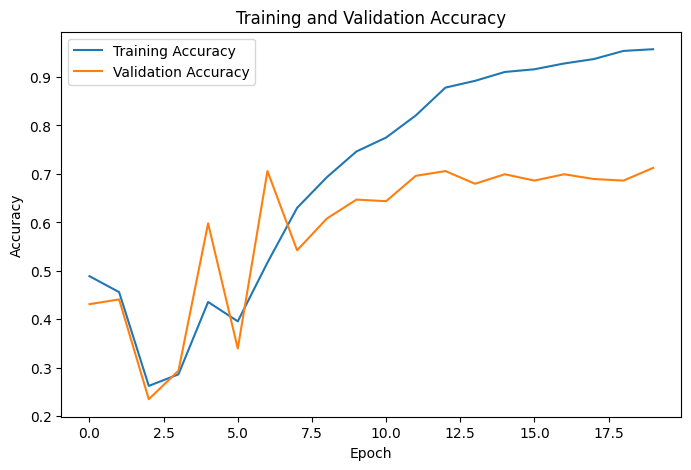

In [ ]:
#training and validation accurracy
import matplotlib.pyplot as plt

# Accuracy graph
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

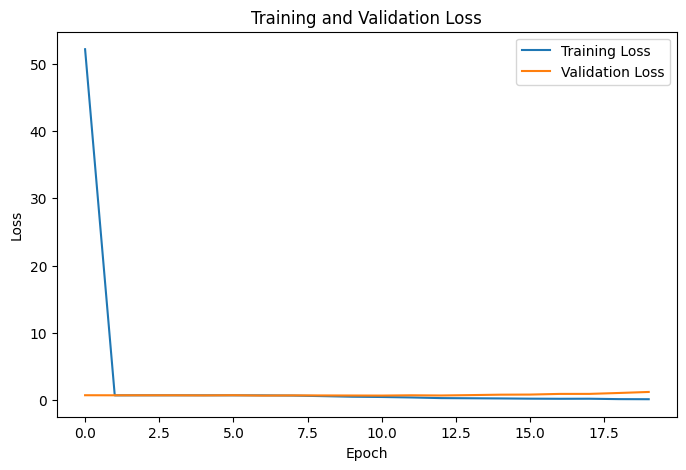

In [ ]:
#training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(test_data)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

10/10 ━━━━━━━━━━━━━━━━━━━━ 7s 664ms/step - accuracy: 0.7451 - loss: 0.9050
Test Loss: 0.9050452709197998
Test Accuracy: 0.7450980544090271


In [ ]:
#Generate Predictions
import numpy as np

y_true = []
y_pred = []

for images, labels in test_data:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy().flatten())
    y_pred.extend((predictions.flatten() >= 0.5).astype(int))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Actual labels:", y_true[:10])
print("Predicted labels:", y_pred[:10])

Actual labels: [1. 0. 1. 1. 1. 1. 0. 1. 0. 1.]
Predicted labels: [1 1 1 1 1 1 0 1 0 1]


In [ ]:
#Classification Report
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=["Class 0", "Class 1"]
))

              precision    recall  f1-score   support

     Class 0       0.45      0.38      0.41        72
     Class 1       0.82      0.86      0.84       234

    accuracy                           0.75       306
   macro avg       0.63      0.62      0.62       306
weighted avg       0.73      0.75      0.74       306



[[ 27  45]
 [ 33 201]]


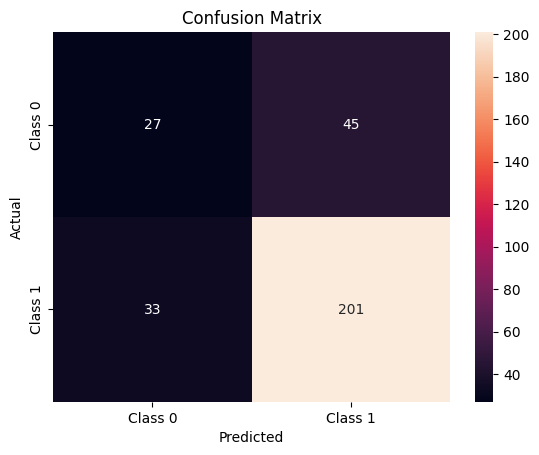

In [ ]:
#confusion matrix
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

print(cm)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

ALEXNET MODEL

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

alexnet = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    # Data normalization
    layers.Rescaling(1.0 / 255),

    # Mild data augmentation
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),

    # AlexNet Convolution Block 1
    layers.Conv2D(
        96,
        kernel_size=(11, 11),
        strides=(4, 4),
        activation="relu",
        padding="same"
    ),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(3, 3), strides=(2, 2)),

    # AlexNet Convolution Block 2
    layers.Conv2D(
        256,
        kernel_size=(5, 5),
        padding="same",
        activation="relu"
    ),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(3, 3), strides=(2, 2)),

    # AlexNet Convolution Block 3
    layers.Conv2D(
        384,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),

    # AlexNet Convolution Block 4
    layers.Conv2D(
        384,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),

    # AlexNet Convolution Block 5
    layers.Conv2D(
        256,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(3, 3), strides=(2, 2)),

    # Convert feature maps into a vector
    layers.Flatten(),

    # Fully connected layers
    layers.Dense(
        4096,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.0001)
    ),
    layers.Dropout(0.5),

    layers.Dense(
        4096,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.0001)
    ),
    layers.Dropout(0.5),

    # Binary classification output
    layers.Dense(1, activation="sigmoid")
])

alexnet.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 56, 56, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 56, 56, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 27, 27, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 27, 27, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 27, 27, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 13, 13, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 13, 13, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 13, 13, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4096)           │    37,752,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         4,097 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,286,849 (222.35 MB)

 Trainable params: 58,286,145 (222.34 MB)

 Non-trainable params: 704 (2.75 KB)

In [ ]:
alexnet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("AlexNet compiled successfully!")

AlexNet compiled successfully!


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping_alexnet = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_alexnet = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

In [ ]:
#creating class weights
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Get labels from training dataset
y_train = []

for images, labels in train_data:
    y_train.extend(labels.numpy().flatten())

y_train = np.array(y_train).astype(int)

# Calculate class weights
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)

Class weights: {np.int64(0): np.float64(2.129850746268657), np.int64(1): np.float64(0.6533882783882784)}


In [ ]:
history_alexnet = alexnet.fit(
    train_data,
    validation_data=val_data,
    epochs=20,
    class_weight=class_weights,
    callbacks=[
        early_stopping_alexnet,
        reduce_lr_alexnet
    ]
)

Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 114s 2s/step - accuracy: 0.5564 - loss: 1.7957 - val_accuracy: 0.2418 - val_loss: 1.6011 - learning_rate: 1.0000e-04
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 112s 2s/step - accuracy: 0.5599 - loss: 1.5831 - val_accuracy: 0.7647 - val_loss: 1.5482 - learning_rate: 1.0000e-04
Epoch 3/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 113s 3s/step - accuracy: 0.5936 - loss: 1.5314 - val_accuracy: 0.7647 - val_loss: 1.5034 - learning_rate: 1.0000e-04
Epoch 4/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 112s 2s/step - accuracy: 0.5943 - loss: 1.4744 - val_accuracy: 0.7647 - val_loss: 1.4407 - learning_rate: 1.0000e-04
Epoch 5/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 112s 2s/step - accuracy: 0.6762 - loss: 1.4335 - val_accuracy: 0.7810 - val_loss: 1.4608 - learning_rate: 1.0000e-04
Epoch 6/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 111s 2s/step - accuracy: 0.6321 - loss: 1.4058 - val_accuracy: 0.7647 - val_loss: 1.4269 - learning_rate: 1.0000e-04
Epoch 7/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 111s 2s/step - accuracy: 0.6734 

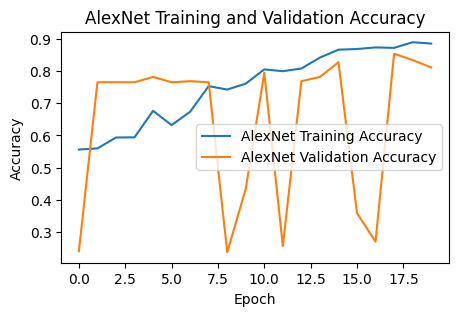

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 3))

plt.plot(
    history_alexnet.history["accuracy"],
    label="AlexNet Training Accuracy"
)

plt.plot(
    history_alexnet.history["val_accuracy"],
    label="AlexNet Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("AlexNet Training and Validation Accuracy")
plt.legend()
plt.show()

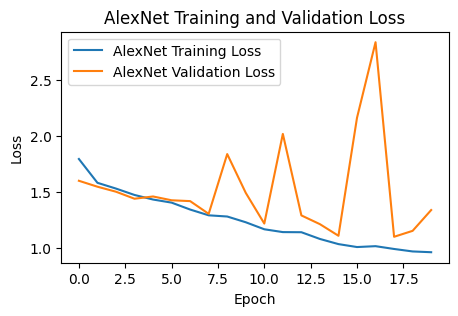

In [ ]:
plt.figure(figsize=(5, 3))

plt.plot(
    history_alexnet.history["loss"],
    label="AlexNet Training Loss"
)

plt.plot(
    history_alexnet.history["val_loss"],
    label="AlexNet Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("AlexNet Training and Validation Loss")
plt.legend()
plt.show()

In [ ]:
alexnet_test_loss, alexnet_test_accuracy = alexnet.evaluate(test_data)

print("AlexNet Test Loss:", alexnet_test_loss)
print("AlexNet Test Accuracy:", alexnet_test_accuracy)

10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 480ms/step - accuracy: 0.8660 - loss: 1.0312
AlexNet Test Loss: 1.0312063694000244
AlexNet Test Accuracy: 0.8660130500793457


[[ 51  21]
 [ 20 214]]


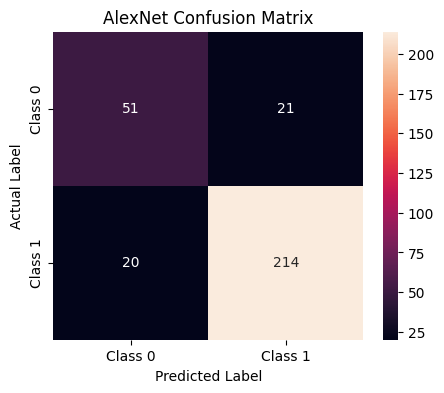

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm_alexnet = confusion_matrix(
    y_true_alexnet,
    y_pred_alexnet
)

print(cm_alexnet)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_alexnet,
    annot=True,
    fmt="d",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("AlexNet Confusion Matrix")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true_alexnet,
        y_pred_alexnet,
        target_names=["Class 0", "Class 1"]
    )
)

              precision    recall  f1-score   support

     Class 0       0.72      0.71      0.71        72
     Class 1       0.91      0.91      0.91       234

    accuracy                           0.87       306
   macro avg       0.81      0.81      0.81       306
weighted avg       0.87      0.87      0.87       306



ERROR ANALYSIS FOR ALEXNET MODEL

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Store actual labels and predicted probabilities
y_true_alexnet = []
y_prob_alexnet = []

for images, labels in test_data:
    predictions = alexnet.predict(images, verbose=0).flatten()

    y_true_alexnet.extend(labels.numpy().flatten())
    y_prob_alexnet.extend(predictions)

# Convert to numpy arrays
y_true_alexnet = np.array(y_true_alexnet).astype(int)
y_prob_alexnet = np.array(y_prob_alexnet)

# Convert probabilities to predicted classes
y_pred_alexnet = (y_prob_alexnet >= 0.5).astype(int)

print("Total test images:", len(y_true_alexnet))
print("Correct predictions:", np.sum(y_true_alexnet == y_pred_alexnet))
print("Wrong predictions:", np.sum(y_true_alexnet != y_pred_alexnet))

Total test images: 306
Correct predictions: 265
Wrong predictions: 41


/tmp/ipykernel_393/2934656465.py:10: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  actual = int(labels[i].numpy())


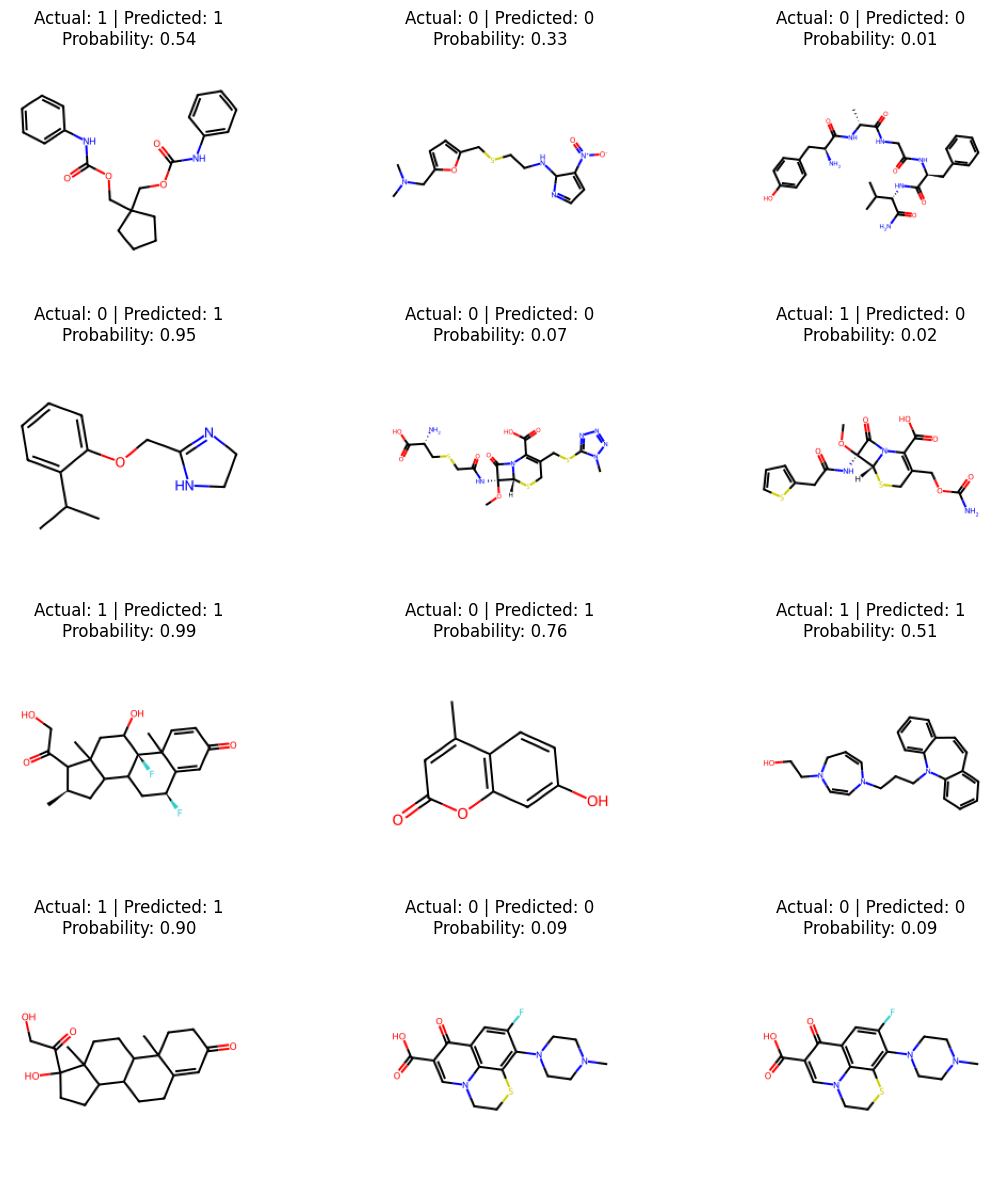

In [ ]:
# Visualize first 12 test predictions

plt.figure(figsize=(12, 12))

for i in range(12):
    images, labels = next(iter(test_data))

    predictions = alexnet.predict(images, verbose=0).flatten()

    actual = int(labels[i].numpy())
    probability = predictions[i]
    predicted = int(probability >= 0.5)

    plt.subplot(4, 3, i + 1)

    # Convert TensorFlow image to numpy
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.axis("off")

    plt.title(
        f"Actual: {actual} | Predicted: {predicted}\n"
        f"Probability: {probability:.2f}"
    )

plt.tight_layout()
plt.show()

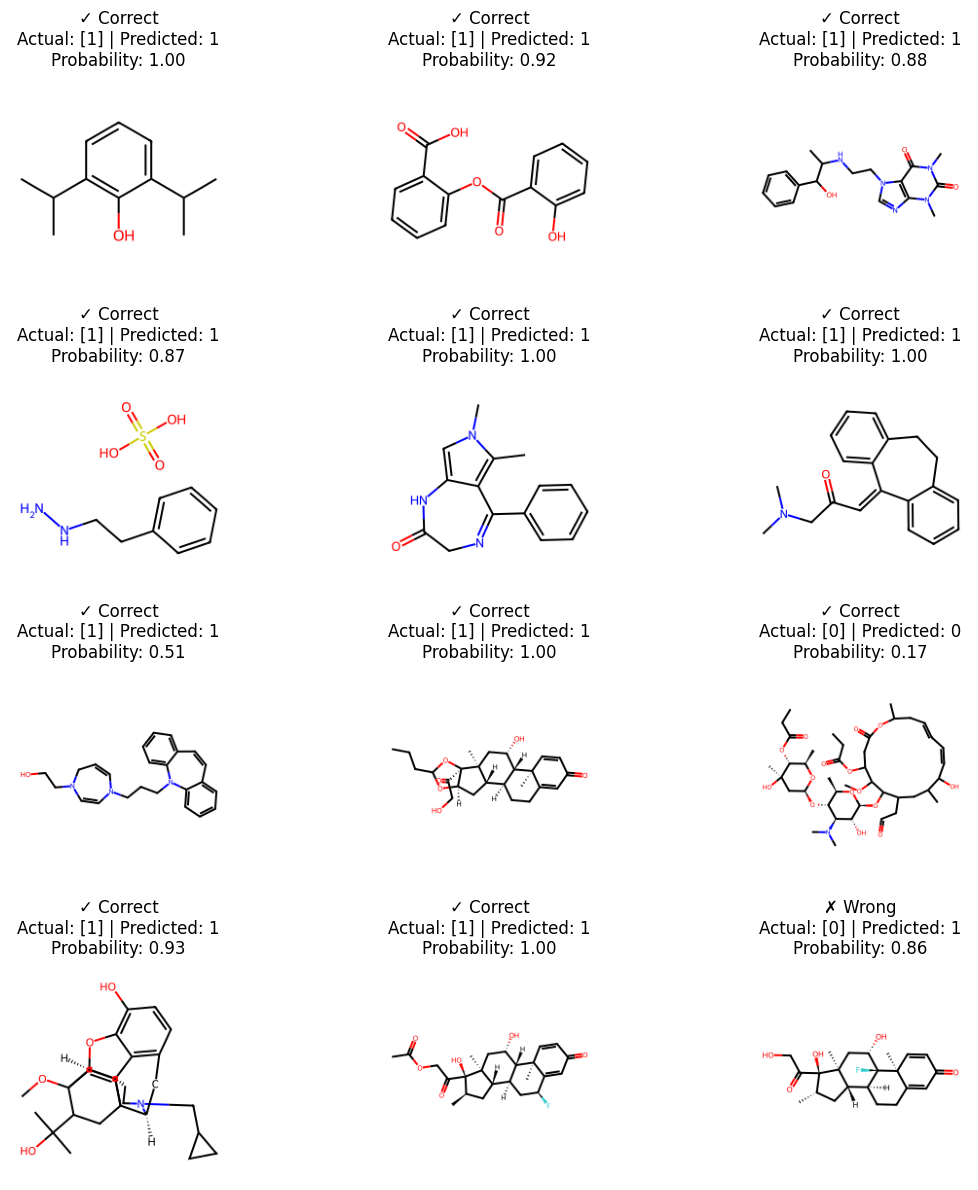

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Get one batch from test data
for images, labels in test_data.take(1):

    predictions = alexnet.predict(images, verbose=0).flatten()

    actual_labels = labels.numpy().astype(int)
    predicted_labels = (predictions >= 0.5).astype(int)

    plt.figure(figsize=(12, 12))

    for i in range(min(12, len(images))):

        plt.subplot(4, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.axis("off")

        actual = actual_labels[i]
        predicted = predicted_labels[i]
        probability = predictions[i]

        status = "✓ Correct" if actual == predicted else "✗ Wrong"

        plt.title(
            f"{status}\n"
            f"Actual: {actual} | Predicted: {predicted}\n"
            f"Probability: {probability:.2f}"
        )

    plt.tight_layout()
    plt.show()

In [ ]:
import tensorflow as tf
import numpy as np

test_data_fixed = tf.keras.utils.image_dataset_from_directory(
    "/content/dataset/test",
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary",
    shuffle=False
)

test_files = np.array(test_data_fixed.file_paths)

print("Number of test images:", len(test_files))

Found 306 files belonging to 2 classes.
Number of test images: 306


In [ ]:
y_true_alexnet = []
y_prob_alexnet = []

for images, labels in test_data_fixed:
    predictions = alexnet.predict(images, verbose=0).flatten()

    y_true_alexnet.extend(labels.numpy().flatten())
    y_prob_alexnet.extend(predictions)

y_true_alexnet = np.array(y_true_alexnet).astype(int)
y_prob_alexnet = np.array(y_prob_alexnet)

y_pred_alexnet = (y_prob_alexnet >= 0.5).astype(int)

print("Total predictions:", len(y_pred_alexnet))

Total predictions: 306


In [ ]:
error_0_to_1 = np.where(
    (y_true_alexnet == 0) & (y_pred_alexnet == 1)
)[0]

error_1_to_0 = np.where(
    (y_true_alexnet == 1) & (y_pred_alexnet == 0)
)[0]

print("0 → 1 errors:", len(error_0_to_1))
print("1 → 0 errors:", len(error_1_to_0))

0 → 1 errors: 21
1 → 0 errors: 20


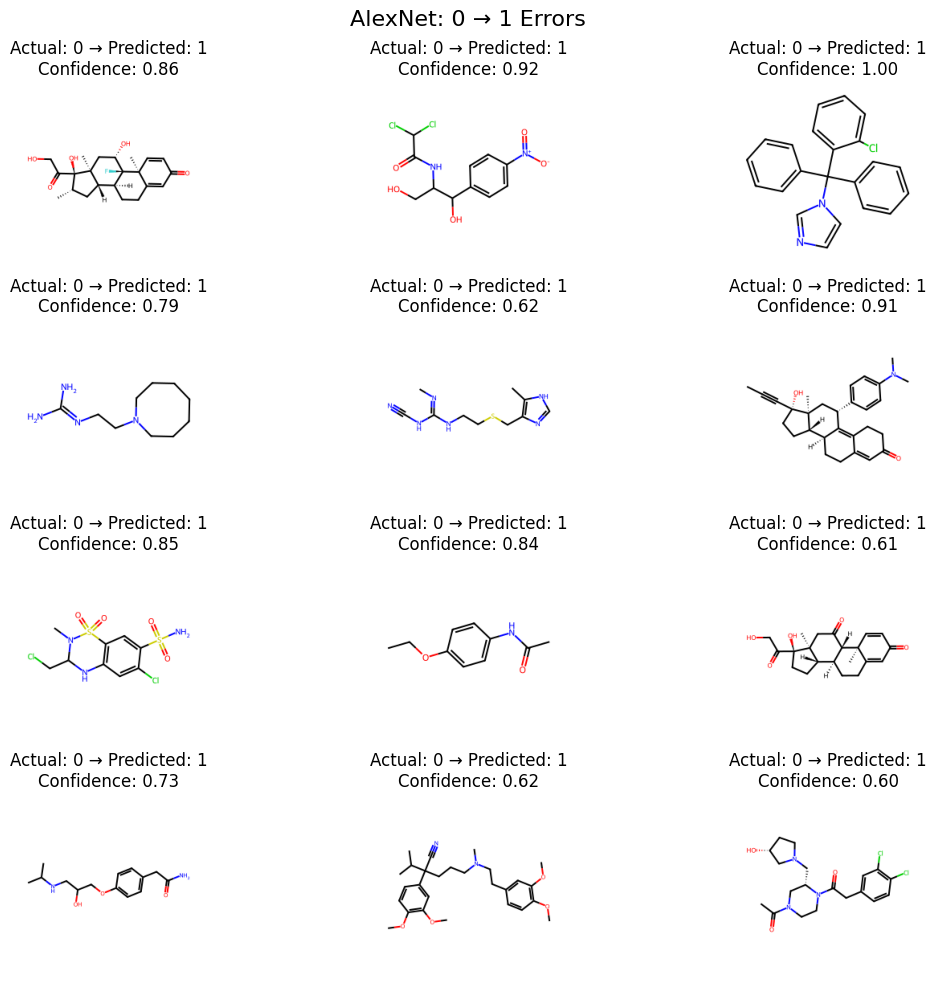

In [ ]:
#Visualize 0 → 1 errors
import matplotlib.pyplot as plt
from PIL import Image

plt.figure(figsize=(12, 10))

for i, idx in enumerate(error_0_to_1[:12]):

    img = Image.open(test_files[idx])

    plt.subplot(4, 3, i + 1)
    plt.imshow(img)
    plt.axis("off")

    probability = y_prob_alexnet[idx]

    plt.title(
        f"Actual: 0 → Predicted: 1\n"
        f"Confidence: {probability:.2f}"
    )

plt.suptitle("AlexNet: 0 → 1 Errors", fontsize=16)
plt.tight_layout()
plt.show()

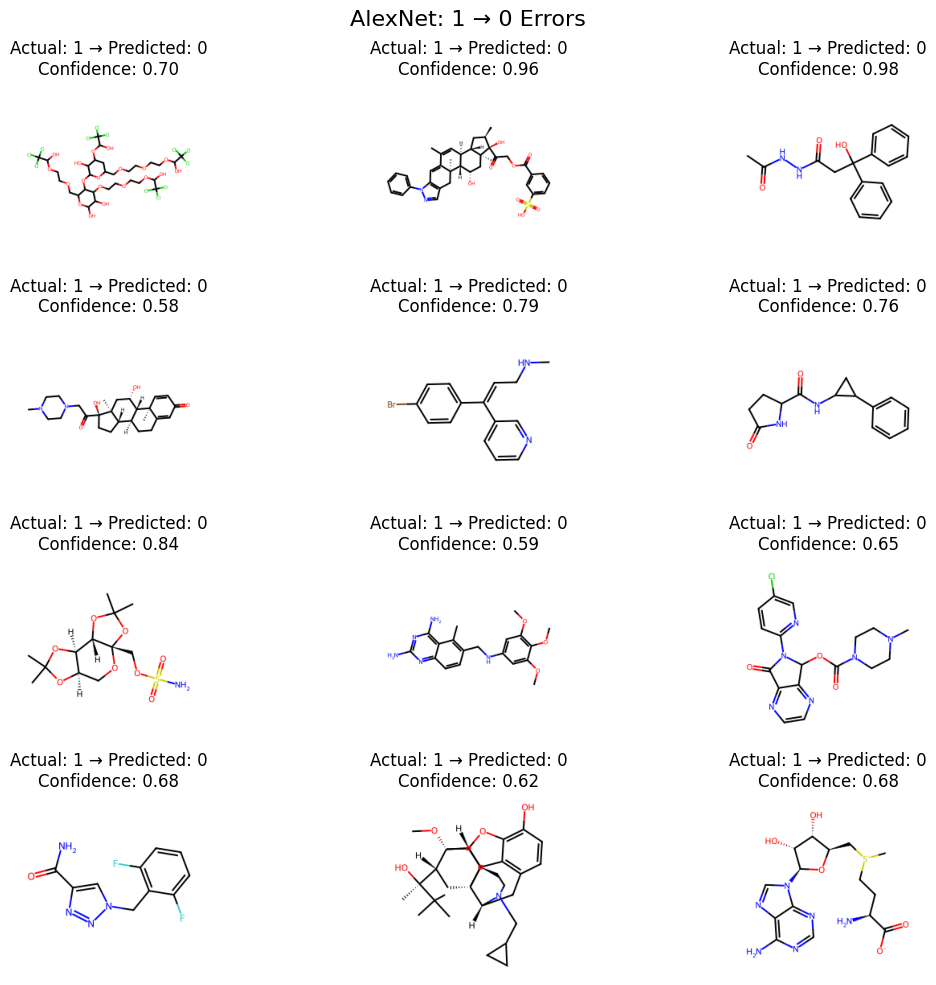

In [ ]:
#Visualize 1 → 0 errors
plt.figure(figsize=(12, 10))

for i, idx in enumerate(error_1_to_0[:12]):

    img = Image.open(test_files[idx])

    plt.subplot(4, 3, i + 1)
    plt.imshow(img)
    plt.axis("off")

    probability = y_prob_alexnet[idx]
    confidence = 1 - probability

    plt.title(
        f"Actual: 1 → Predicted: 0\n"
        f"Confidence: {confidence:.2f}"
    )

plt.suptitle("AlexNet: 1 → 0 Errors", fontsize=16)
plt.tight_layout()
plt.show()

OBSERVATION IN THE ERROR ANALYSIS: AlexNet produced both 0→1 and 1→0 classification errors. Some incorrectly classified molecular structure images showed similar visual patterns between the two classes. The confidence values also showed that some errors occurred with relatively high confidence, indicating that the model sometimes learned misleading visual features.

INCEPTION MODEL

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.applications.inception_v3 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [ ]:
inception_base = InceptionV3(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

inception_base.trainable = False

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
inception_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.RandomRotation(0.03),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),

    layers.Lambda(preprocess_input),

    inception_base,

    layers.GlobalAveragePooling2D(),

    layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(0.0001)
    ),

    layers.BatchNormalization(),
    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

In [ ]:
inception_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
inception_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 5, 5, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_94          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,328,609 (85.18 MB)

 Trainable params: 525,313 (2.00 MB)

 Non-trainable params: 21,803,296 (83.17 MB)

In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])
class_counts = np.array([479, 1560])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=np.repeat(classes, class_counts)
)

class_weights = {
    0: weights[0],
    1: weights[1]
}

print("Class weights:", class_weights)

Class weights: {0: np.float64(2.12839248434238), 1: np.float64(0.653525641025641)}


In [ ]:
early_stopping_inception = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_inception = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

In [ ]:
history_inception = inception_model.fit(
    train_data,
    validation_data=val_data,
    epochs=20,
    class_weight=class_weights,
    callbacks=[
        early_stopping_inception,
        reduce_lr_inception
    ]
)

Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 310s 7s/step - accuracy: 0.5704 - loss: 0.8624 - val_accuracy: 0.8039 - val_loss: 0.4923 - learning_rate: 1.0000e-04
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 301s 7s/step - accuracy: 0.6370 - loss: 0.6907 - val_accuracy: 0.8137 - val_loss: 0.4732 - learning_rate: 1.0000e-04
Epoch 3/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 273s 6s/step - accuracy: 0.6307 - loss: 0.7083 - val_accuracy: 0.8039 - val_loss: 0.4712 - learning_rate: 1.0000e-04
Epoch 4/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 251s 6s/step - accuracy: 0.6804 - loss: 0.6630 - val_accuracy: 0.8497 - val_loss: 0.4499 - learning_rate: 1.0000e-04
Epoch 5/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 262s 6s/step - accuracy: 0.7036 - loss: 0.6119 - val_accuracy: 0.8431 - val_loss: 0.4482 - learning_rate: 1.0000e-04
Epoch 6/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 305s 7s/step - accuracy: 0.6685 - loss: 0.6235 - val_accuracy: 0.8562 - val_loss: 0.4350 - learning_rate: 1.0000e-04
Epoch 7/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 254s 6s/step - accuracy: 0.7239 

In [ ]:
inception_test_loss, inception_test_accuracy = inception_model.evaluate(test_data)

print("InceptionV3 Test Loss:", inception_test_loss)
print("InceptionV3 Test Accuracy:", inception_test_accuracy)
print(
    "InceptionV3 Test Accuracy Percentage:",
    inception_test_accuracy * 100
)

10/10 ━━━━━━━━━━━━━━━━━━━━ 45s 4s/step - accuracy: 0.8105 - loss: 0.4856
InceptionV3 Test Loss: 0.4856090545654297
InceptionV3 Test Accuracy: 0.8104575276374817
InceptionV3 Test Accuracy Percentage: 81.04575276374817


**VGG16** MODEL

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [ ]:
vgg16_base = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

vgg16_base.trainable = False

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
vgg16 = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.RandomRotation(0.03),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),

    layers.Lambda(preprocess_input),

    vgg16_base,

    layers.GlobalAveragePooling2D(),

    layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(0.0001)
    ),

    layers.BatchNormalization(),
    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

In [ ]:
vgg16.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
vgg16.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,847,297 (56.64 MB)

 Trainable params: 132,097 (516.00 KB)

 Non-trainable params: 14,715,200 (56.13 MB)

In [ ]:
#recreating class weights
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])
class_counts = np.array([479, 1560])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=np.repeat(classes, class_counts)
)

class_weights = {
    0: weights[0],
    1: weights[1]
}

print("Class weights:", class_weights)

Class weights: {0: np.float64(2.12839248434238), 1: np.float64(0.653525641025641)}


In [ ]:
#creating callbacks
early_stopping_vgg16 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_vgg16 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

In [ ]:
history_vgg16 = vgg16.fit(
    train_data,
    validation_data=val_data,
    epochs=20,
    class_weight=class_weights,
    callbacks=[
        early_stopping_vgg16,
        reduce_lr_vgg16
    ]
)

Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 326s 7s/step - accuracy: 0.5389 - loss: 0.8839 - val_accuracy: 0.6046 - val_loss: 0.8274 - learning_rate: 1.0000e-04
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 326s 7s/step - accuracy: 0.6076 - loss: 0.7574 - val_accuracy: 0.6078 - val_loss: 0.7765 - learning_rate: 1.0000e-04
Epoch 3/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 324s 7s/step - accuracy: 0.6020 - loss: 0.7222 - val_accuracy: 0.6634 - val_loss: 0.6799 - learning_rate: 1.0000e-04
Epoch 4/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 326s 7s/step - accuracy: 0.6475 - loss: 0.6890 - val_accuracy: 0.6503 - val_loss: 0.7242 - learning_rate: 1.0000e-04
Epoch 5/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 324s 7s/step - accuracy: 0.6335 - loss: 0.6686 - val_accuracy: 0.6569 - val_loss: 0.6595 - learning_rate: 1.0000e-04
Epoch 6/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 332s 7s/step - accuracy: 0.6713 - loss: 0.6471 - val_accuracy: 0.6242 - val_loss: 0.6910 - learning_rate: 1.0000e-04
Epoch 7/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.6621 - 

In [ ]:
vgg16_test_loss, vgg16_test_accuracy = vgg16.evaluate(test_data)

print("VGG16 Test Loss:", vgg16_test_loss)
print("VGG16 Test Accuracy:", vgg16_test_accuracy)
print("VGG16 Test Accuracy Percentage:", vgg16_test_accuracy * 100)

10/10 ━━━━━━━━━━━━━━━━━━━━ 56s 6s/step - accuracy: 0.7647 - loss: 0.6256
VGG16 Test Loss: 0.6255763173103333
VGG16 Test Accuracy: 0.7647058963775635
VGG16 Test Accuracy Percentage: 76.47058963775635


In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Get predictions
y_prob_vgg16 = vgg16.predict(test_data)

# Convert probabilities to class labels
y_pred_vgg16 = (y_prob_vgg16 > 0.5).astype(int).flatten()

# Get actual labels
y_true_vgg16 = np.concatenate([
    y.numpy().astype(int).flatten()
    for x, y in test_data
])

print("Classification Report - VGG16")
print(
    classification_report(
        y_true_vgg16,
        y_pred_vgg16,
        target_names=["Class 0", "Class 1"]
    )
)

10/10 ━━━━━━━━━━━━━━━━━━━━ 57s 6s/step
Classification Report - VGG16
              precision    recall  f1-score   support

     Class 0       0.22      0.39      0.28        72
     Class 1       0.75      0.57      0.65       234

    accuracy                           0.53       306
   macro avg       0.49      0.48      0.47       306
weighted avg       0.63      0.53      0.56       306



In [ ]:
test_data_fixed = tf.keras.utils.image_dataset_from_directory(
    "/content/dataset/test",
    image_size=(224, 224),
    batch_size=32,
    label_mode="binary",
    shuffle=False
)

Found 306 files belonging to 2 classes.


In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Predictions
y_prob_vgg16 = vgg16.predict(test_data_fixed)
y_pred_vgg16 = (y_prob_vgg16 > 0.5).astype(int).flatten()

# True labels
y_true_vgg16 = np.concatenate([
    y.numpy().astype(int).flatten()
    for x, y in test_data_fixed
])

# Classification report
print(classification_report(
    y_true_vgg16,
    y_pred_vgg16,
    target_names=["Class 0", "Class 1"]
))

# Confusion matrix
cm_vgg16 = confusion_matrix(y_true_vgg16, y_pred_vgg16)
print("Confusion Matrix:")
print(cm_vgg16)

10/10 ━━━━━━━━━━━━━━━━━━━━ 57s 6s/step
              precision    recall  f1-score   support

     Class 0       0.50      0.89      0.64        72
     Class 1       0.96      0.73      0.83       234

    accuracy                           0.76       306
   macro avg       0.73      0.81      0.73       306
weighted avg       0.85      0.76      0.78       306

Confusion Matrix:
[[ 64   8]
 [ 64 170]]


TESTING THE MODEL WITH SOME TEST IMAGES

Saving molecule_130.png to molecule_130 (1).png


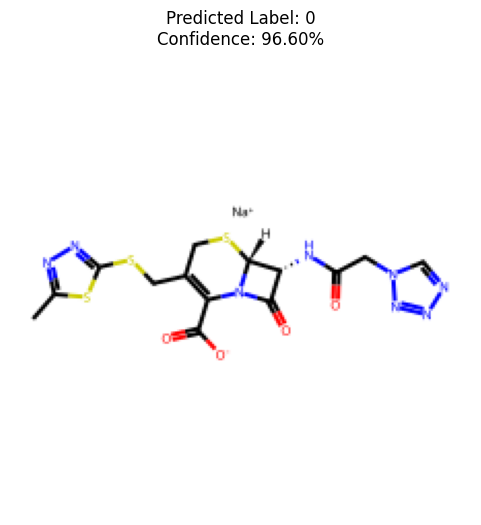

--------------------------------
        ALEXNET PREDICTION
--------------------------------
Predicted Label: 0
Confidence: 96.60%
Meaning: Non-Penetration


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

# Upload image
from google.colab import files
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

# Load image
img = image.load_img(
    image_path,
    target_size=(224, 224)
)

# Convert image to array
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Prediction
probability = alexnet.predict(img_array, verbose=0)[0][0]

# Determine predicted class
if probability >= 0.5:
    predicted_label = 1
    confidence = probability
else:
    predicted_label = 0
    confidence = 1 - probability

# Display image
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")

plt.title(
    f"Predicted Label: {predicted_label}\n"
    f"Confidence: {confidence * 100:.2f}%"
)

plt.show()

print("--------------------------------")
print("        ALEXNET PREDICTION")
print("--------------------------------")
print("Predicted Label:", predicted_label)
print("Confidence:", f"{confidence * 100:.2f}%")

if predicted_label == 1:
    print("Meaning: BBB Penetration")
else:
    print("Meaning: Non-Penetration")

In [ ]:
alexnet.save("/content/alexnet_BBBP.keras")

In [ ]:
from google.colab import files

files.download("/content/alexnet_BBBP.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>